In [1]:
import pathlib 
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

%load_ext autoreload
%autoreload 2

%matplotlib inline

In [3]:
ER_BASEDIR = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R56H10_R20A02_split_GFlamp2_R18B05LexA_CsChrimsontdT')
EPG_BASEDIR = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R60D05Gal4_GFlamp2_R18B05LexA_CsChrimsontdT')

FIGDIR = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/ex_vivo_gflamp')
Group = nmp.group_comparison.Group
GROUPS = {
    'ER': (
        Group('exp', 'ER GFlamp, EL CsChrimsontdT', 'magenta'),
        Group('nocschr_control', 'ER GFlamp, EL no CsChrimson control', plt.cm.Greys(.6), '--', '//'),
        ),
    'EPG': (
        Group('exp', 'EPG GFlamp, EL CsChrimsontdT', 'black'),
        Group('nocschr_control', 'EPG GFlamp, EL no CsChrimson control', plt.cm.Greys(.6), '--', '//'),
    )
}
    
sess_manager_dict = {'ER': nmp.loading.SessionManager(
    basedir=ER_BASEDIR,
    figfolder=FIGDIR,
    folder_cols=('condition',),
    id_cols=('condition', 'cell_type',), extra_cols={'cell_type': 'ER'},
),
'EPG': nmp.loading.SessionManager(
    basedir=EPG_BASEDIR,
    figfolder=FIGDIR,
    folder_cols=('condition',),
    id_cols=('condition', 'cell_type'), extra_cols={'cell_type': 'EPG'},
),
}



In [4]:
from dataclasses import dataclass


@dataclass(frozen=True, eq=False, repr=False)
class OptoResponses:

    fly_id: str
    condition: str
    session: str
    frame_times: np.array 
    stim_times: np.array
    f: np.array
    dff: np.array
    aoc: np.array
    max_dff: np.array
    plot_time: np.array


    def __repr__(self):
        return f"{type(self).__name__}(fly_id={self.fly_id}, condition={self.condition}, session={self.session})"


    @classmethod
    def from_session(cls, fly_id, condition, session, pp):
        frame_times=np.array(pp.metadata['frame_times']).mean(axis=1)
        stim_times=cls._get_stim_times(pp)
        f, dff, aoc, max_dff, plot_time = cls._get_responses(
            pp.timeseries['outer_ring'], 
            frame_times, 
            stim_times,
            )
        
        return cls(
            fly_id=fly_id,
            condition=condition,
            frame_times=frame_times,
            stim_times=stim_times,
            session=session,
            f=f,
            dff=dff,
            aoc=aoc,
            max_dff=max_dff,
            plot_time=plot_time
        )

    @staticmethod
    def _get_stim_times(pp):    
        stim_times = [pp.metadata['mark_points']['initial_delay']/1000,]
        for _ in range(1, pp.metadata['mark_points']['repetitions']):
            stim_times.append(stim_times[-1] + \
                              pp.metadata['mark_points']['duration']/1000 + \
                                pp.metadata['mark_points']['inter_point_delay']/1000)

        return np.squeeze(np.array(stim_times))


    @staticmethod
    def _get_responses(f, frame_times, stim_times, start_time=-2, stop_time=8):
        plot_times = np.arange(start_time, stop_time, .1)

        responses = []
        for stim_time in stim_times:
            id_stim = np.argmin(np.abs(frame_times-stim_time))
            id_start = np.argmin(np.abs(frame_times - (stim_time + start_time)))
            id_end = np.argmin(np.abs(frame_times - (stim_time + stop_time)))

            sample_times = frame_times[id_start:id_end] - frame_times[id_stim]
            _stim_f =  f[-1,0,id_start:id_end]
            

            # put all responses on the same clock
            responses.append(np.interp(plot_times, sample_times, _stim_f))
        responses =  np.vstack([responses])
        
    
        
        mask = (plot_times >= -.2) & (plot_times <= .22)
        baseline_mask = plot_times < -.2
        responses[:,mask] = np.nan
        baseline = np.nanmean(responses[:,baseline_mask],axis=1, keepdims=True)
        dff = responses/baseline -1
        aoc = np.nansum(dff[:,plot_times>.22],axis=-1)
        max_dff = np.amax(dff[:, plot_times>.22], axis=-1)
                
        
        return responses, dff, aoc, max_dff, plot_times






In [ ]:
dff_df = []
for cell_type, sess_manager in sess_manager_dict.items():
    for i, row in sess_manager.sess_df.iterrows():
        pp = sess_manager.load_row(row)
        fly_id = row['fly_id']
        condition = row['condition']
        session = row['session']
        opto_response = OptoResponses.from_session(fly_id, condition, session, pp)

        if i==0:
            plot_time = opto_response.plot_time

        dff_df.append(
            {
                'cell_type': cell_type,
                'fly_id': fly_id,
                'condition': condition,
                'mean_df': opto_response.dff.mean(axis=0),
                'aoc': opto_response.aoc.mean(),
                'max_dff': opto_response.max_dff.mean(),
            }
        )
dff_df = pd.DataFrame(dff_df)


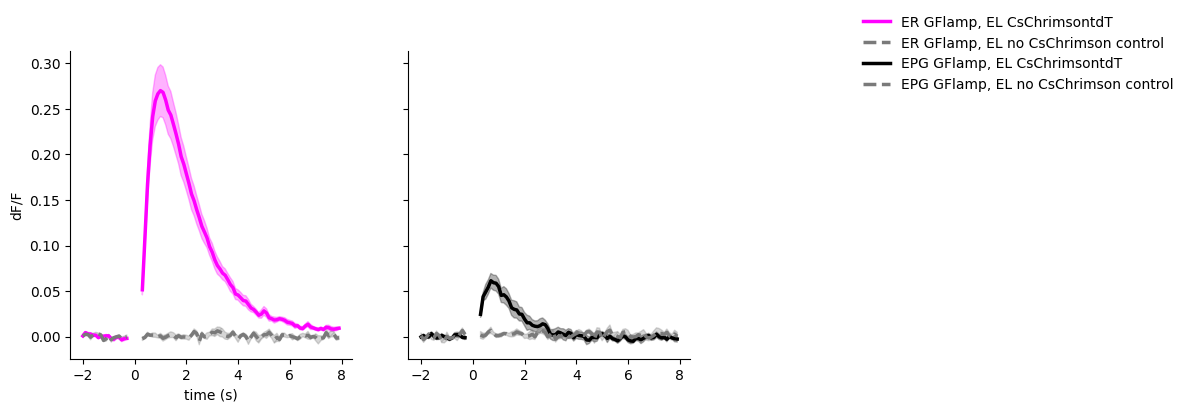

In [23]:
fig, ax = plt.subplots(1,2, figsize=[8,4], sharey=True, sharex=True)

for i, (cell_type, groups) in enumerate(GROUPS.items()):
    cell_type_mask = dff_df['cell_type']==cell_type
    nmp.plotting.despine(ax[i])
    for g in groups:
        _df = dff_df.loc[(dff_df['condition']==g.value)*(cell_type_mask)]
        dff = np.vstack(_df['mean_df'])

        mu, sem = dff.mean(axis=0), sp.stats.sem(dff,axis=0)
        ax[i].plot(plot_time, mu, color=g.color, linestyle=g.linestyle, 
                linewidth=2.5, label=g.label)
        ax[i].fill_between(plot_time, mu-sem, mu+sem, 
                        color=g.color, alpha=.3, hatch=g.hatch)


ax[0].set_ylabel('dF/F')
ax[0].set_xlabel('time (s)')
fig.legend(loc='upper left', bbox_to_anchor=(1.1, 1.0), frameon=False)

(0.0, 0.5)

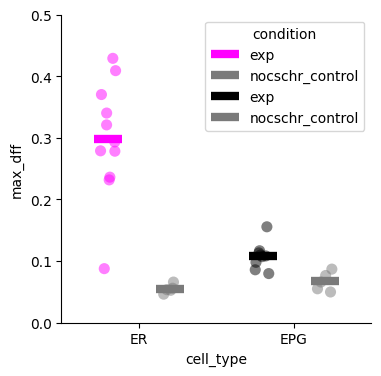

In [22]:
# _df = dff_df.loc[dff_df['condition']=='exp']
# dff_df['cell_type x condition'] = [f"{row['cell_type']} {row['condition']}" for _, row in dff_df.iterrows()]
fig, ax = plt.subplots(figsize=[4,4])
# dff_df['x'] = 1*(dff_df['cell_type']=='ER')
for cell_type, groups in GROUPS.items():
  kw = {
      'data': dff_df.loc[dff_df['cell_type']==cell_type],
      'x': 'cell_type',
      'y': 'max_dff',
      'hue': 'condition', 
      'hue_order': [g.value for g in groups],
      'palette': {g.value: g.color for g in groups},
      }
  

  sns.stripplot(**kw, ax=ax, alpha=.5, dodge=True, s=8, legend=False)
  sns.pointplot(**kw, ax=ax, estimator=np.mean, errorbar=None, 
                marker='_', markersize=20, markeredgewidth=6,
                dodge=.4, linestyle='none', legend=True)
nmp.plotting.despine(ax)
ax.set_ylim([0,.5])


In [29]:
x = dff_df.loc[(dff_df['cell_type']=='ER') * (dff_df['condition']=='exp'),'max_dff']
y = dff_df.loc[(dff_df['cell_type']=='ER') * (dff_df['condition']=='nocschr_control'), 'max_dff']
# print(x,y)
u,p = sp.stats.mannwhitneyu(x,y)

print(f"ER: experimental vs control, u={u} p={p}")

x = dff_df.loc[(dff_df['cell_type']=='EPG') * (dff_df['condition']=='exp'),'max_dff']
y = dff_df.loc[(dff_df['cell_type']=='EPG') * (dff_df['condition']=='nocschr_control'), 'max_dff']
# print(x,y)
u,p = sp.stats.mannwhitneyu(x,y)

print(f"EPG: experimental vs control, u={u} p={p}")

x = dff_df.loc[(dff_df['cell_type']=='ER') * (dff_df['condition']=='exp'),'max_dff']
y = dff_df.loc[(dff_df['cell_type']=='EPG') * (dff_df['condition']=='exp'), 'max_dff']
# print(x,y)
u,p = sp.stats.mannwhitneyu(x,y)

print(f"EPG vs ER: u={u} p={p}")

ER: experimental vs control, u=55.0 p=0.0004578754578754579
EPG: experimental vs control, u=43.0 p=0.003996003996003996
EPG vs ER: u=92.0 p=0.0014183225546052331
